# Etapa 7a — Medidas clínicas: definirlas con los expertos

Las tres medidas están en `src/clinical.py` y se calculan igual sobre cualquier máscara, dentro del campo de visión de la base:
- **proporción de vasos** en el campo;
- **longitud del esqueleto** dividida por el diámetro del campo;
- **tortuosidad:** en cada tramo del esqueleto entre bifurcaciones, el largo del camino dividido por la distancia en línea recta; el resumen por imagen es la mediana.

Antes del esqueleto se rellenan los agujeros de menos de 40 × 40 píxeles (por ejemplo, el reflejo del centro de los vasos gruesos), y el largo de cada tramo se mide con una poligonal que toma un punto cada 6 píxeles, para que un vaso recto en diagonal no salga tortuoso por los escalones de los píxeles.

Este cuaderno fija, **solo con las máscaras de los expertos de las 30 imágenes de desarrollo** y antes de mirar las del algoritmo (esquema, etapa 7), los dos parámetros que el esquema dejaba abiertos (en píxeles a resolución original, con el diámetro de referencia de 3262; en `config` van en proporción al diámetro):
- **poda:** se sacan las ramitas (con una punta libre y pegadas a una bifurcación) más cortas que P píxeles. Candidatas 5, 10, 20 y 40; sin poda, como comparación;
- **largo mínimo:** los tramos más cortos que L píxeles no entran en la tortuosidad. Candidatas 25, 50, 100 y 200.

**Cómo se elige (fijado antes de correr).** Para cada parámetro, el valor más chico tal que pasar al siguiente (el doble) deja casi igual la tortuosidad por imagen: correlación de rangos de Spearman de al menos 0,95 entre las 30 imágenes. Primero la poda, con el largo mínimo provisorio de 50; después el largo mínimo, con la poda elegida. Si ninguno cumple, el mayor. Si con el largo elegido alguna imagen queda con menos de 20 tramos, se toma el anterior.


In [1]:
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as C
from src.data import dev_ids, load_split
from src.evaluation import map_images

ids = dev_ids()
dev = load_split().set_index("image").loc[ids]
SPURS, MINS, REF = [0, 5, 10, 20, 40], [25, 50, 100, 200], C.FOV_DIAMETER_REF

In [2]:
def measure(image_id):
    import numpy as np
    from src.clinical import clean_skeleton, segment_lengths, skeleton_length
    from src.data import load_fov, load_vessels
    from src.fov import fov_diameter
    truth, fov = load_vessels(image_id), load_fov(image_id)
    d = fov_diameter(fov)
    rows = []
    for sp in SPURS:
        skel = clean_skeleton(truth, fov, d, sp / REF)
        arc, chord = segment_lengths(skel, d)
        for mn in MINS:
            keep = (arc >= mn / REF * d) & (chord > 0)
            t = arc[keep] / chord[keep]
            rows.append({"image": image_id, "poda": sp, "largo mínimo": mn, "tramos": int(keep.sum()),
                         "tortuosidad": float(np.median(t)) if len(t) else np.nan,
                         "longitud": skeleton_length(skel) / d})
    return rows

t = time.time()
R = pd.DataFrame([r for rows in map_images(measure, ids, workers=4) for r in rows])
R.to_csv(ROOT / "results" / "07a_parametros_expertos.csv", index=False)
print(f"{time.time() - t:.0f} s")
print("Tortuosidad media (de las medianas por imagen):")
R.pivot_table(index="poda", columns="largo mínimo", values="tortuosidad").round(4)

401 s
Tortuosidad media (de las medianas por imagen):


largo mínimo,25,50,100,200
poda,,,,
0,1.0180,1.0199,1.0237,1.0307
5,1.0182,1.0200,1.0240,1.0314
10,1.0183,1.0202,1.0242,1.0317
20,1.0185,1.0204,1.0244,1.0322
40,1.0192,1.0209,1.0251,1.0333


In [3]:
print("Tramos por imagen (el mínimo entre las 30):")
R.pivot_table(index="poda", columns="largo mínimo", values="tramos", aggfunc="min")

Tramos por imagen (el mínimo entre las 30):


largo mínimo,25,50,100,200
poda,,,,
0,354,314,209,56
5,352,312,218,67
10,351,311,217,67
20,351,311,217,69
40,339,309,216,77


In [4]:
wide = R.pivot_table(index="image", columns=["poda", "largo mínimo"], values="tortuosidad")
def spearman(a, b):
    return a.rank().corr(b.rank())

spur_steps = {f"{a} → {b}": spearman(wide[(a, 50)], wide[(b, 50)]) for a, b in zip(SPURS[1:], SPURS[2:])}
print("Poda (largo mínimo 50), Spearman con la siguiente:", {k: round(v, 3) for k, v in spur_steps.items()})
spur = next((a for (a, b) in zip(SPURS[1:], SPURS[2:]) if spearman(wide[(a, 50)], wide[(b, 50)]) >= 0.95), SPURS[-1])

min_steps = {f"{a} → {b}": spearman(wide[(spur, a)], wide[(spur, b)]) for a, b in zip(MINS, MINS[1:])}
print(f"Largo mínimo (poda {spur}), Spearman con el siguiente:", {k: round(v, 3) for k, v in min_steps.items()})
min_len = next((a for a, b in zip(MINS, MINS[1:]) if spearman(wide[(spur, a)], wide[(spur, b)]) >= 0.95), MINS[-1])
fewest = R[(R["poda"] == spur) & (R["largo mínimo"] == min_len)]["tramos"].min()
if fewest < 20 and min_len != MINS[0]:
    min_len = MINS[MINS.index(min_len) - 1]
print(f"Elegidos: poda {spur} píxeles, largo mínimo {min_len} píxeles (tramos en la imagen con menos: {fewest})")

Poda (largo mínimo 50), Spearman con la siguiente: {'5 → 10': np.float64(0.998), '10 → 20': np.float64(0.996), '20 → 40': np.float64(0.991)}
Largo mínimo (poda 5), Spearman con el siguiente: {'25 → 50': np.float64(0.959), '50 → 100': np.float64(0.959), '100 → 200': np.float64(0.873)}
Elegidos: poda 5 píxeles, largo mínimo 25 píxeles (tramos en la imagen con menos: 352)


## Las medidas de los expertos con los parámetros elegidos

In [5]:
E = R[(R["poda"] == spur) & (R["largo mínimo"] == min_len)].set_index("image")
def proportion(image_id):
    from src.data import load_fov, load_vessels
    truth, fov = load_vessels(image_id), load_fov(image_id)
    return image_id, float((truth & fov).sum() / fov.sum())
E["proporción"] = pd.Series(dict(map_images(proportion, ids, workers=4)))
E = E.join(dev[["group", "more_compressed"]])
print("Por grupo (media):")
print(E.groupby("group")[["proporción", "longitud", "tortuosidad", "tramos"]].mean().round(4).to_string())
print("\nPor grupo y compresión (media; cantidad de imágenes):")
E.groupby(["more_compressed", "group"]).agg(imágenes=("tortuosidad", "size"), proporción=("proporción", "mean"),
                                           longitud=("longitud", "mean"), tortuosidad=("tortuosidad", "mean")).round(4)

Por grupo (media):
       proporción  longitud  tortuosidad  tramos
group                                           
dr         0.0846   24.4529       1.0190   548.1
g          0.0813   24.4193       1.0162   593.0
h          0.1099   23.6836       1.0193   536.7

Por grupo y compresión (media; cantidad de imágenes):


imágenes  proporción  longitud  tortuosidad
more_compressed group                                             
False           dr            8      0.0854   24.0778       1.0190
                g             6      0.0767   22.8543       1.0150
                h             4      0.1185   24.2581       1.0190
True            dr            2      0.0815   25.9534       1.0188
                g             4      0.0881   26.7667       1.0180
                h             6      0.1041   23.3007       1.0196

## Control a ojo: los tramos de una imagen con retinopatía

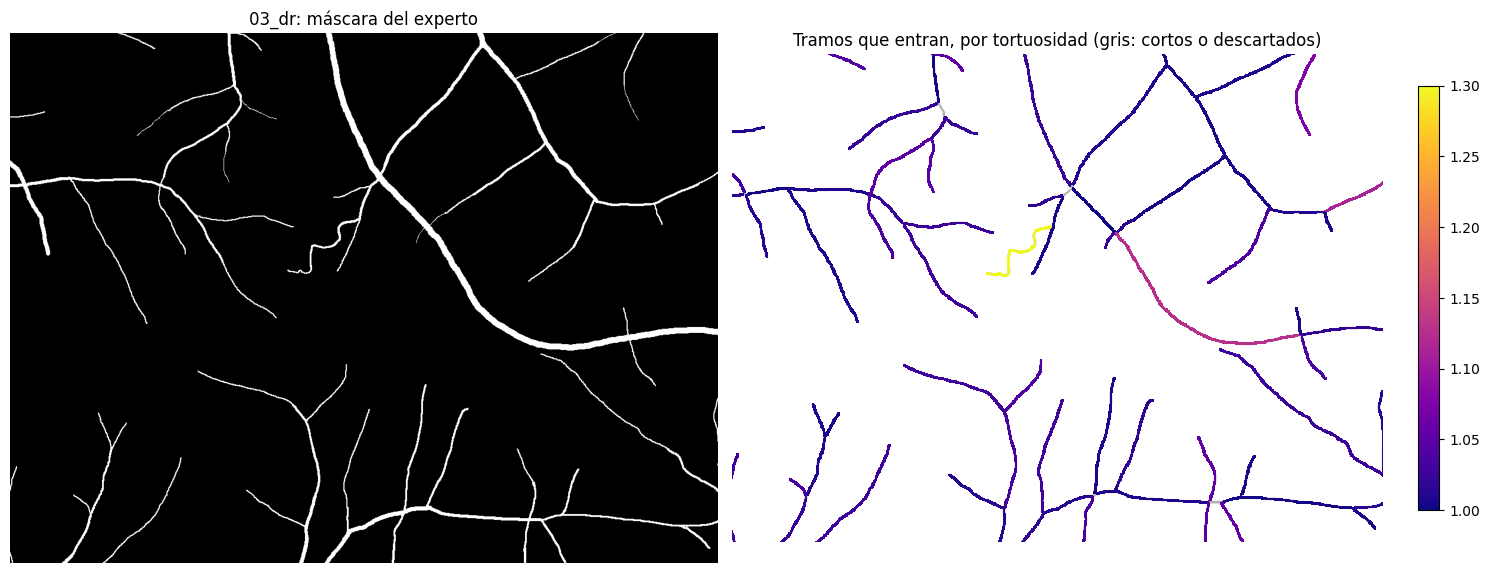

In [6]:
from src.clinical import clean_skeleton, ordered_paths, path_length, segments
from src.data import load_fov, load_vessels
from src.fov import fov_diameter

img = dev.index[dev["group"] == "dr"][0]
truth, fov = load_vessels(img), load_fov(img)
d = fov_diameter(fov)
skel = clean_skeleton(truth, fov, d, spur / REF)
labels, n = segments(skel)
tort = np.full(n + 1, np.nan)
for k, p in ordered_paths(labels, n).items():
    arc, chord = path_length(p, C.CLINICAL_STEP_REL * d), np.hypot(*(p[-1] - p[0]))
    if arc >= min_len / REF * d and chord > 0:
        tort[k] = arc / chord
r0, c0, h, w = 700, 1700, 900, 1200
from scipy import ndimage as ndi
thick = ndi.maximum_filter(labels, size=5)          # tramos engrosados para que se vean
show = np.where(thick > 0, tort[thick], np.nan)[r0:r0 + h, c0:c0 + w]
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].imshow(truth[r0:r0 + h, c0:c0 + w], cmap="gray"); ax[0].set_title(f"{img}: máscara del experto")
ax[1].imshow(ndi.binary_dilation(skel, iterations=2)[r0:r0 + h, c0:c0 + w], cmap="gray_r", alpha=0.3)
im = ax[1].imshow(np.ma.masked_invalid(show), cmap="plasma", vmin=1.0, vmax=1.3, interpolation="nearest")
ax[1].set_title("Tramos que entran, por tortuosidad (gris: cortos o descartados)")
for a in ax: a.axis("off")
fig.colorbar(im, ax=ax[1], fraction=0.03); plt.tight_layout(); plt.show()

## Decisión (por la regla fijada antes de correr)

- **Poda: 5 píxeles.** Pasar a 10 deja la tortuosidad por imagen igual (Spearman 0,998). Las máscaras de los expertos casi no tienen ramitas: sin poda o con 40 píxeles la tortuosidad media cambia en la cuarta cifra.
- **Largo mínimo: 25 píxeles.** Pasar a 50 da Spearman 0,959. Con ese largo, la imagen con menos tramos tiene 352.
- Quedan en `config` (`CLINICAL_SPUR_REL`, `CLINICAL_MIN_SEGMENT_REL`), en proporción al diámetro.

**Lo que muestran los expertos** (para leer la etapa 7b):
- La **tortuosidad** casi no cambia entre grupos (retinopatía 1,019, glaucoma 1,016, sanos 1,019): en esta base no separa sanos de enfermos.
- La **proporción de vasos** es mayor en los sanos (11,0 % contra 8,5 % y 8,1 %), pero la **longitud del esqueleto**, que no depende del ancho, no (23,7 contra 24,5 y 24,4 diámetros). La diferencia en proporción viene del ancho con que se marcaron los sanos (etapa 1c), no de que tengan más vasos.
- La tortuosidad sube con el largo mínimo (de 1,018 con 25 a 1,031 con 200): los tramos largos son más curvos. Por eso el largo mínimo tiene que ser el mismo para los expertos y para el algoritmo, como se hace.
